<a href="https://colab.research.google.com/github/aisyahihsani/social-media-event-detector/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Social Media Crisis Event Detector

## Project Overview
This project aims to detect crisis-related events from social media posts using Natural Language Processing (NLP).

The system will classify crisis-related posts, represent their semantic meaning using text embeddings, and group related posts into potential events.

## Objectives
1. Identify crisis-related social media posts.
2. Represent posts using semantic embeddings.
3. Cluster posts that describe similar events.
4. Detect emerging events from grouped posts.
5. Generate meaningful event summaries.

## Technologies
- Python
- Pandas
- NumPy
- Scikit-learn
- TensorFlow / Transformers
- Sentence-BERT
- Google Colab

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
!pip install -q datasets

In [5]:
from datasets import load_dataset

dataset = load_dataset(
    "QCRI/CrisisBench-english",
    "informativeness"
)

print(dataset)

README.md:   0%|          | 0.00/7.69k [00:00<?, ?B/s]

informativeness/test.json: reconstructing file:   0%|          |  0.00B / 10.6MB            

informativeness/test.json: downloading bytes:           |  0.00B            

informativeness/dev.json: reconstructing file:   0%|          |  0.00B / 5.44MB            

informativeness/dev.json: downloading bytes:           |  0.00B            

informativeness/train.json: reconstructing file:   0%|          |  0.00B / 37.3MB            

informativeness/train.json: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/31095 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/16008 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/109796 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['id', 'event', 'source', 'text', 'lang', 'lang_conf', 'class_label'],
        num_rows: 31095
    })
    dev: Dataset({
        features: ['id', 'event', 'source', 'text', 'lang', 'lang_conf', 'class_label'],
        num_rows: 16008
    })
    train: Dataset({
        features: ['id', 'event', 'source', 'text', 'lang', 'lang_conf', 'class_label'],
        num_rows: 109796
    })
})


1. EXPLORATORY DATA ANALYSIS (EDA)

In [6]:
train_df = dataset["train"].to_pandas()

print("Dataset shape:", train_df.shape)
print("\nColumn names:")
print(train_df.columns.tolist())

train_df.head()

Dataset shape: (109796, 7)

Column names:
['id', 'event', 'source', 'text', 'lang', 'lang_conf', 'class_label']


,id,event,source,text,lang,lang_conf,class_label
0,530,disaster_events,drd-figureeight-multimedia,"Organization that are working in Haiti, I do n...",en,1,informative
1,913070034204884992,hurricane_maria,crisismmd,Maria now a hurricane again!! Strong storm sur...,en,NA,informative
2,540027128478044160,2014_philippines_typhoon,crisisnlp-cf,RT @ANCALERTS: Fallen tree branches scattered ...,en,0.9505285620689392,informative
3,17711,disaster_events,drd-figureeight-multimedia,The Government did not request international a...,en,1,informative
4,778251007,disaster_events,dsm-cf,Remove http://t.co/77b2rNRTt7 Browser Hijacker...,en,1,not_informative


In [7]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109796 entries, 0 to 109795
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   id           109796 non-null  object
 1   event        109796 non-null  object
 2   source       109796 non-null  object
 3   text         109796 non-null  object
 4   lang         109796 non-null  object
 5   lang_conf    109796 non-null  object
 6   class_label  109796 non-null  object
dtypes: object(7)
memory usage: 5.9+ MB


In [8]:
train_df["class_label"].value_counts()

,count
class_label,
informative,65826
not_informative,43970


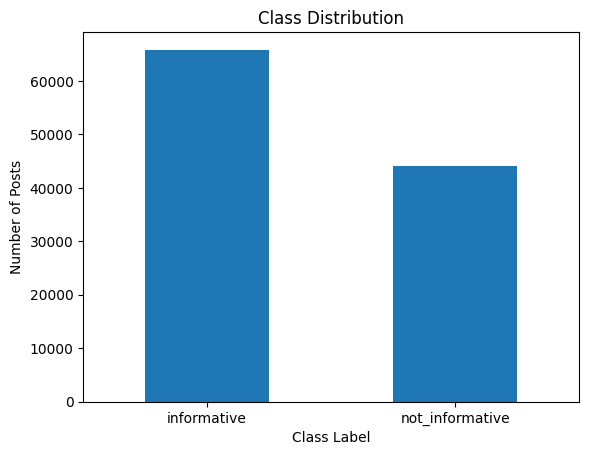

In [9]:
label_counts = train_df["class_label"].value_counts()

label_counts.plot(
    kind="bar",
    title="Class Distribution",
    xlabel="Class Label",
    ylabel="Number of Posts"
)

plt.xticks(rotation=0)
plt.show()

In [10]:
label_percentages = (
    train_df["class_label"]
    .value_counts(normalize=True) * 100
)

print(label_percentages.round(2))

class_label
informative        59.95
not_informative    40.05
Name: proportion, dtype: float64


In [11]:
train_df[["event", "text", "class_label"]].sample(
    10,
    random_state=42
)

,event,text,class_label
86757,2014_philippines_typhoon-hagupit,Slowly moving 'Ruby' to bring torrential rains...,not_informative
89674,2015_nepal_earthquake,MT @dineshakula Med supplies required in Bir H...,informative
21192,2013_phillipines_typhoon-yolanda,The Chinese Embassy in Manila express condolen...,informative
36556,2014-2015_worldwide_landslides,Rwanda remembers genocide victims 20 years on ...,not_informative
6666,hurricane_harvey,"FOX NEWS' NEW SHOW: ""OBJECTIFIED"" - With - Har...",not_informative
12479,2013_phillipines_typhoon-yolanda,RT @doh_philippines: Dead bodies do not pose a...,informative
22182,2013_oklahoma_tornado-ontopic,RT @MannyGzalez: @Frantzy_Pants @danilopz15 I...,not_informative
104210,srilanka_floods,I am Groot... I am Groot. I am Groot! EncuÃ©nt...,not_informative
23615,2015_nepal_earthquake,Another natural disaster causing carnage. Poor...,informative
93115,2013_west_texas,@gomezisourangel: Explosion in Texas? WHAT? I ...,informative


In [12]:
print("Number of unique events:",
      train_df["event"].nunique())

train_df["event"].value_counts().head(10)

Number of unique events: 61


,count
event,
disaster_events,25399
2015_nepal_earthquake,7760
2012_sandy_hurricane-ontopic,6206
2013_oklahoma_tornado-ontopic,6179
2013_alberta_floods-ontopic,6072
2013_boston_bombings-ontopic,5916
2013_west_texas,5657
2014_philippines_typhoon-hagupit,5164
2013_queensland_floods-ontopic,4628


In [13]:
train_df["lang"].value_counts().head(10)

,count
lang,
en,109796


In [14]:
train_df["text_length"] = train_df["text"].str.len()

print(train_df["text_length"].describe())

count    109796.000000
mean        106.233296
std          49.714009
min           5.000000
25%          75.000000
50%         111.000000
75%         136.000000
max        4153.000000
Name: text_length, dtype: float64


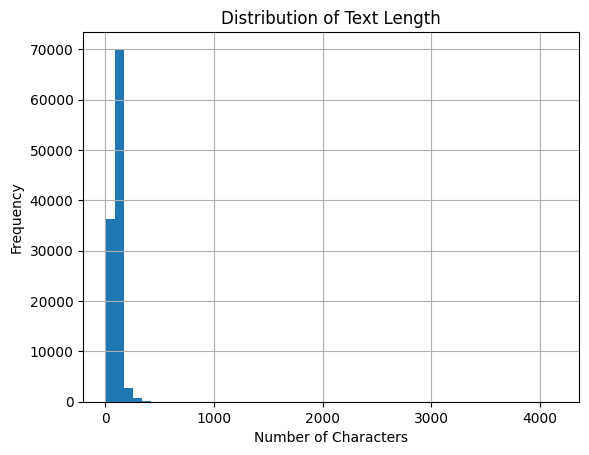

In [15]:
train_df["text_length"].hist(bins=50)

plt.title("Distribution of Text Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

The class distribution analysis showed that the dataset contains 65,826 informative posts and 43,970 not-informative posts. Informative posts represent approximately 59.95% of the dataset, while not-informative posts account for 40.05%. Although the classes are not perfectly balanced, the distribution is relatively moderate. Therefore, the dataset can be used for binary classification, while precision, recall, and F1-score should also be considered during evaluation.

In [16]:
sample_posts = train_df[
    ["event", "text", "class_label"]
].sample(
    10,
    random_state=42
)

sample_posts

,event,text,class_label
86757,2014_philippines_typhoon-hagupit,Slowly moving 'Ruby' to bring torrential rains...,not_informative
89674,2015_nepal_earthquake,MT @dineshakula Med supplies required in Bir H...,informative
21192,2013_phillipines_typhoon-yolanda,The Chinese Embassy in Manila express condolen...,informative
36556,2014-2015_worldwide_landslides,Rwanda remembers genocide victims 20 years on ...,not_informative
6666,hurricane_harvey,"FOX NEWS' NEW SHOW: ""OBJECTIFIED"" - With - Har...",not_informative
12479,2013_phillipines_typhoon-yolanda,RT @doh_philippines: Dead bodies do not pose a...,informative
22182,2013_oklahoma_tornado-ontopic,RT @MannyGzalez: @Frantzy_Pants @danilopz15 I...,not_informative
104210,srilanka_floods,I am Groot... I am Groot. I am Groot! EncuÃ©nt...,not_informative
23615,2015_nepal_earthquake,Another natural disaster causing carnage. Poor...,informative
93115,2013_west_texas,@gomezisourangel: Explosion in Texas? WHAT? I ...,informative


In [17]:
# Count the number of unique event labels
number_of_events = train_df["event"].nunique()

print("Number of unique events:", number_of_events)

# Display the 10 most frequent event labels
train_df["event"].value_counts().head(10)

Number of unique events: 61


,count
event,
disaster_events,25399
2015_nepal_earthquake,7760
2012_sandy_hurricane-ontopic,6206
2013_oklahoma_tornado-ontopic,6179
2013_alberta_floods-ontopic,6072
2013_boston_bombings-ontopic,5916
2013_west_texas,5657
2014_philippines_typhoon-hagupit,5164
2013_queensland_floods-ontopic,4628


The event distribution analysis identified 61 unique event labels in the training dataset. The number of posts varied across events, with some events containing substantially more samples than others. The most frequent label was `disaster_events`, followed by specific events such as the 2015 Nepal Earthquake and Hurricane Sandy. This analysis provides an initial understanding of the dataset's event structure and may support future event clustering experiments. However, general event labels should be examined carefully before being used as ground truth for clustering evaluation.

In [18]:
# Count the number of unique event labels
number_of_events = train_df["event"].nunique()

print("Number of unique events:", number_of_events)

# Display the 10 most frequent events
train_df["event"].value_counts().head(10)

Number of unique events: 61


,count
event,
disaster_events,25399
2015_nepal_earthquake,7760
2012_sandy_hurricane-ontopic,6206
2013_oklahoma_tornado-ontopic,6179
2013_alberta_floods-ontopic,6072
2013_boston_bombings-ontopic,5916
2013_west_texas,5657
2014_philippines_typhoon-hagupit,5164
2013_queensland_floods-ontopic,4628


In [19]:
# Count the number of posts for each language
language_counts = train_df["lang"].value_counts()

# Display the 10 most common languages
language_counts.head(10)

,count
lang,
en,109796


The language distribution analysis confirmed that the dataset contains English-language posts only. Therefore, language filtering is not required for the current dataset. This allows the project to focus on English text preprocessing and modelling without introducing additional complexity from multilingual data.

In [20]:
# Calculate the number of characters in each post
train_df["text_length"] = train_df["text"].str.len()

# Display descriptive statistics
train_df["text_length"].describe()

,text_length
count,109796.000000
mean,106.233296
std,49.714009
min,5.000000
25%,75.000000
50%,111.000000
75%,136.000000
max,4153.000000
